# 09 · Síntesis: comparación entre los tres análisis

**Sección de la tesis:** 6.5 (Comparación entre los tres análisis).

Este notebook no ajusta modelos: lee las tablas que generaron los notebooks 04 a 07 y las reúne, de modo que la síntesis siempre coincide con los resultados de cada análisis.

**Salidas:** tablas S-T1 y S-T2; figuras S-F1 y S-F2; `ORDEN_DE_RESULTADOS.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

In [2]:
def leer(codigo):
    """Lee una tabla de resultados ya guardada, por su código."""
    archivo = next(TABLAS.glob(f"{codigo}_*.csv"))
    return pd.read_csv(archivo)

## 1. ¿Cuánta información añade la estrella en cada análisis?

Para cada pregunta se compara el modelo base con el modelo estelar (base + $M_\star$ + [Fe/H]; en el zoom, además la interacción con el flujo).

In [3]:
def fila(tabla, modelo):
    return tabla.set_index("modelo").loc[modelo]

a1, z, z_vc = fila(leer("A1-T4"), "B1"), fila(leer("Z-T3"), "M2"), fila(leer("Z-T5"), "M2")
a2, a2_vc = fila(leer("A2-T2"), "M2"), fila(leer("A2-T3"), "M2")
s1, g1 = fila(leer("A3-T5"), "S1"), fila(leer("A3-T7"), "G1")

sintesis = pd.DataFrame([
    {"analisis": "I. Regímenes de radio", "respuesta": "clase_radio (5 regímenes)", "tipo_de_modelo": "logístico multinomial",
     "N": int(a1["N_planetas"]), "unidad": "planetas", "base": "logP", "estelar": "B1: + st_mass + st_met",
     "delta_AIC": a1["delta_AIC"], "medida_de_ajuste": "pseudo-R2", "delta_ajuste": a1["delta_pseudo_R2"],
     "medida_de_error": "log-loss", "delta_error_muestra": a1["delta_log_loss"], "delta_error_vc": np.nan},
    {"analisis": "I. Super-Tierras y sub-Neptunos", "respuesta": "sub_neptune_conservador", "tipo_de_modelo": "logístico binario",
     "N": int(z["N_planetas"]), "unidad": "planetas", "base": "logF", "estelar": "M2: + st_mass + st_met + logF x st_mass",
     "delta_AIC": z["delta_AIC"], "medida_de_ajuste": "pseudo-R2", "delta_ajuste": z["delta_pseudo_R2"],
     "medida_de_error": "log-loss", "delta_error_muestra": z["delta_log_loss"], "delta_error_vc": z_vc["delta_log_loss_vc"]},
    {"analisis": "II. Propiedades físicas", "respuesta": "log_Mp", "tipo_de_modelo": "lineal con spline",
     "N": int(a2["N_planetas"]), "unidad": "planetas", "base": "s(log_Rp) + logF", "estelar": "M2: + st_mass + st_met",
     "delta_AIC": a2["delta_AIC"], "medida_de_ajuste": "R2", "delta_ajuste": a2["delta_R2"],
     "medida_de_error": "RMSE [dex]", "delta_error_muestra": a2["delta_RMSE"], "delta_error_vc": a2_vc["delta_RMSE_vc"]},
    {"analisis": "III. Espaciamiento orbital", "respuesta": "log_median_period_ratio", "tipo_de_modelo": "lineal",
     "N": int(s1["N_sistemas"]), "unidad": "sistemas", "base": "median_radius + N_planetas", "estelar": "S1: + st_mass + st_met",
     "delta_AIC": s1["delta_AIC"], "medida_de_ajuste": "R2", "delta_ajuste": s1["delta_R2"],
     "medida_de_error": "RMSE [dex]", "delta_error_muestra": s1["delta_RMSE"], "delta_error_vc": np.nan},
    {"analisis": "III. Sistemas gapped", "respuesta": "gapped", "tipo_de_modelo": "logístico binario",
     "N": int(g1["N_sistemas"]), "unidad": "sistemas", "base": "median_radius + N_planetas", "estelar": "G1: + st_mass + st_met",
     "delta_AIC": g1["delta_AIC"], "medida_de_ajuste": "pseudo-R2", "delta_ajuste": g1["delta_pseudo_R2"],
     "medida_de_error": "log-loss", "delta_error_muestra": g1["delta_log_loss"], "delta_error_vc": np.nan},
])
tabla_sintesis = guardar_tabla(
    sintesis, "S-T1", "sintesis_contribucion_estelar",
    titulo="Contribución de las propiedades estelares en los tres análisis: cambio del modelo estelar respecto al modelo base.",
    seccion="6.5",
    nota=("Valores negativos de AIC y de las medidas de error indican mejora. VC: validación cruzada agrupada por estrella "
          "(solo donde varios planetas comparten estrella)."),
    encabezados={"tipo_de_modelo": "Modelo", "unidad": "Unidad", "base": "Base", "estelar": "Estelar",
                 "medida_de_ajuste": "Ajuste", "delta_ajuste": r"$\Delta$ajuste", "medida_de_error": "Error",
                 "delta_error_muestra": r"$\Delta$error", "delta_error_vc": r"$\Delta$error VC"},
    formatos={"delta_AIC": "{:+.1f}", "delta_ajuste": "{:+.4f}", "delta_error_muestra": "{:+.4f}", "delta_error_vc": "{:+.4f}"})
tabla_sintesis

Tabla S-T1 guardada: tablas/S-T1_sintesis_contribucion_estelar.csv


,analisis,respuesta,tipo_de_modelo,N,unidad,base,estelar,delta_AIC,medida_de_ajuste,delta_ajuste,medida_de_error,delta_error_muestra,delta_error_vc
0,I. Regímenes de radio,clase_radio (5 regímenes),logístico multinomial,4461,planetas,logP,B1: + st_mass + st_met,-1067.4947,pseudo-R2,0.0872,log-loss,-0.1214,NaN
1,I. Super-Tierras y sub-Neptunos,sub_neptune_conservador,logístico binario,2565,planetas,logF,M2: + st_mass + st_met + logF x st_mass,-376.7341,pseudo-R2,0.1176,log-loss,-0.0746,-0.0730
2,II. Propiedades físicas,log_Mp,lineal con spline,535,planetas,s(log_Rp) + logF,M2: + st_mass + st_met,-1.2386,R2,0.0049,RMSE [dex],-0.0013,0.0003
3,III. Espaciamiento orbital,log_median_period_ratio,lineal,615,sistemas,median_radius + N_planetas,S1: + st_mass + st_met,-11.3230,R2,0.0229,RMSE [dex],-0.0031,NaN
4,III. Sistemas gapped,gapped,logístico binario,615,sistemas,median_radius + N_planetas,G1: + st_mass + st_met,-6.2816,pseudo-R2,0.0208,log-loss,-0.0084,NaN


## 2. Dirección y tamaño de los efectos estelares

Efecto de un aumento de una desviación estándar (DE) de $M_\star$ y de [Fe/H] en cada modelo estelar. En los modelos logísticos el efecto es una razón (RRR u OR; 1 = sin efecto); en los lineales, un cambio en dex (0 = sin efecto). En el zoom se usa el modelo aditivo M1.

In [4]:
efectos = []

def agregar(analisis, contraste, medida, tabla, col, inf, sup, filtro):
    for f in tabla[filtro(tabla)].itertuples():
        efectos.append({"analisis": analisis, "contraste": contraste, "medida": medida,
                        "predictor": "st_mass" if "mass" in f.predictor.lower() or "Mstar" in f.predictor else "st_met",
                        "efecto": getattr(f, col), "IC95_inf": getattr(f, inf), "IC95_sup": getattr(f, sup), "valor_p": f.valor_p})

estelar = lambda t: t["predictor"].isin(["st_mass_z", "st_met_z"])
coef_I = leer("A1-T5")
for clase in [c for c in CLASES_RADIO if c != CLASE_REFERENCIA]:
    agregar("I. Regímenes de radio", f"{ETIQUETA_CLASE[clase]} vs super-Tierra", "RRR", coef_I,
            "RRR", "RRR_IC95_inf", "RRR_IC95_sup", lambda t, c=clase: estelar(t) & (t["clase_radio"] == c))
momios = leer("Z-T7")
agregar("I. Super-Tierras y sub-Neptunos", "Sub-Neptuno vs super-Tierra", "OR", momios, "OR", "OR_IC95_inf", "OR_IC95_sup",
        lambda t: (t["modelo"] == "M1") & t["incremento"].str.startswith("+1 DE") & t["predictor"].isin(["Mstar_c", "FeH_c"]))
agregar("II. Propiedades físicas", "log_Mp", "coeficiente [dex]", leer("A2-T4"), "coeficiente", "IC95_inf", "IC95_sup",
        lambda t: (t["modelo"] == "M2") & estelar(t))
agregar("III. Espaciamiento orbital", "log_median_period_ratio", "coeficiente [dex]", leer("A3-T6"), "coeficiente", "IC95_inf", "IC95_sup", estelar)
agregar("III. Sistemas gapped", "Gapped vs no gapped", "OR", leer("A3-T8"), "OR", "OR_IC95_inf", "OR_IC95_sup", estelar)

tabla_efectos = guardar_tabla(
    pd.DataFrame(efectos), "S-T2", "efectos_estelares_por_analisis",
    titulo="Efecto de un aumento de una desviación estándar de la masa estelar y de la metalicidad en el modelo estelar de cada análisis.",
    seccion="6.5",
    nota="RRR y OR: 1 indica ausencia de efecto. Coeficientes en dex: 0 indica ausencia de efecto. Intervalos de confianza al 95 %.",
    encabezados={"contraste": "Respuesta o contraste", "medida": "Medida", "efecto": "Efecto"})
tabla_efectos

Tabla S-T2 guardada: tablas/S-T2_efectos_estelares_por_analisis.csv


,analisis,contraste,medida,predictor,efecto,IC95_inf,IC95_sup,valor_p
0,I. Regímenes de radio,Terrestre vs super-Tierra,RRR,st_mass,0.8335,0.7399,0.9389,2.730000e-03
1,I. Regímenes de radio,Terrestre vs super-Tierra,RRR,st_met,0.8705,0.7809,0.9703,1.230000e-02
2,I. Regímenes de radio,Tipo Neptuno vs super-Tierra,RRR,st_mass,1.0870,0.9895,1.1941,8.180000e-02
3,I. Regímenes de radio,Tipo Neptuno vs super-Tierra,RRR,st_met,1.2580,1.1559,1.3690,1.060000e-07
4,I. Regímenes de radio,Gigante gaseoso vs super-Tierra,RRR,st_mass,1.8602,1.6445,2.1042,5.660000e-23
5,I. Regímenes de radio,Gigante gaseoso vs super-Tierra,RRR,st_met,2.1460,1.9153,2.4045,1.470000e-39
6,I. Regímenes de radio,Mayor que Júpiter vs super-Tierra,RRR,st_mass,8.8797,7.0077,11.2517,4.730000e-73
7,I. Regímenes de radio,Mayor que Júpiter vs super-Tierra,RRR,st_met,0.8853,0.7170,1.0932,2.580000e-01
8,I. Super-Tierras y sub-Neptunos,Sub-Neptuno vs super-Tierra,OR,st_mass,2.6713,2.3344,3.0569,2.770000e-46
9,I. Super-Tierras y sub-Neptunos,Sub-Neptuno vs super-Tierra,OR,st_met,1.1439,1.0293,1.2713,1.260000e-02


Figura S-F2 guardada: figuras/S-F2_efectos_estelares_en_los_tres_analisis.png y .pdf


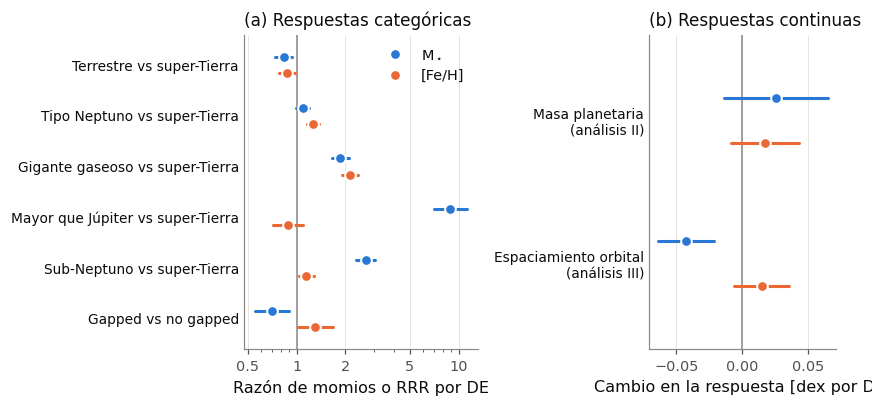

In [5]:
ef = pd.DataFrame(efectos)
COLOR = {"st_mass": COLOR_MASA_ESTELAR, "st_met": COLOR_METALICIDAD}
ETIQUETA = {"st_mass": r"$M_\star$", "st_met": "[Fe/H]"}

def panel(ax, datos_panel, referencia):
    contrastes = list(dict.fromkeys(datos_panel["contraste"]))
    linea_referencia(ax, referencia)
    for i, contraste in enumerate(contrastes):
        y_base = len(contrastes) - 1 - i
        for predictor, dy in [("st_mass", 0.16), ("st_met", -0.16)]:
            f = datos_panel[(datos_panel["contraste"] == contraste) & (datos_panel["predictor"] == predictor)].iloc[0]
            ax.plot([f["IC95_inf"], f["IC95_sup"]], [y_base + dy] * 2, color=COLOR[predictor], linewidth=2)
            ax.plot(f["efecto"], y_base + dy, "o", color=COLOR[predictor], markersize=7, markeredgecolor="white",
                    markeredgewidth=1.3, label=ETIQUETA[predictor] if i == 0 else None)
    ax.set_yticks(range(len(contrastes)))
    ax.set_yticklabels(contrastes[::-1], fontsize=9)
    ax.set_ylim(-0.6, len(contrastes) - 0.4)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0, labelcolor=TINTA)

razones = ef[ef["medida"].isin(["RRR", "OR"])]
lineales = ef[ef["medida"].str.startswith("coeficiente")].copy()
lineales["contraste"] = lineales["contraste"].map({"log_Mp": "Masa planetaria\n(análisis II)",
                                                   "log_median_period_ratio": "Espaciamiento orbital\n(análisis III)"})
fig, ejes = plt.subplots(1, 2, figsize=(7.8, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
panel(ejes[0], razones, 1.0)
ejes[0].set_xscale("log")
ejes[0].set_xticks([0.5, 1, 2, 5, 10])
ejes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ejes[0].xaxis.set_minor_formatter(plt.NullFormatter())
ejes[0].set_xlabel("Razón de momios o RRR por DE")
ejes[0].legend(loc="upper right")
etiqueta_panel(ejes[0], "a", "Respuestas categóricas")
panel(ejes[1], lineales, 0.0)
ejes[1].set_xlabel("Cambio en la respuesta [dex por DE]")
etiqueta_panel(ejes[1], "b", "Respuestas continuas")
fig.tight_layout()
guardar_figura(fig, "S-F2", "efectos_estelares_en_los_tres_analisis",
               titulo=("Efecto de un aumento de una desviación estándar de la masa estelar (azul) y de la metalicidad (naranja) en los "
                       "modelos estelares de los tres análisis. (a) Razones de momios o de riesgo relativo, en escala logarítmica; "
                       "(b) coeficientes de los modelos lineales. Las barras son intervalos de confianza al 95 %."),
               seccion="6.5")
plt.show()

## 3. Figura de síntesis del análisis I

Figura S-F1 guardada: figuras/S-F1_sintesis_analisis_I.png y .pdf


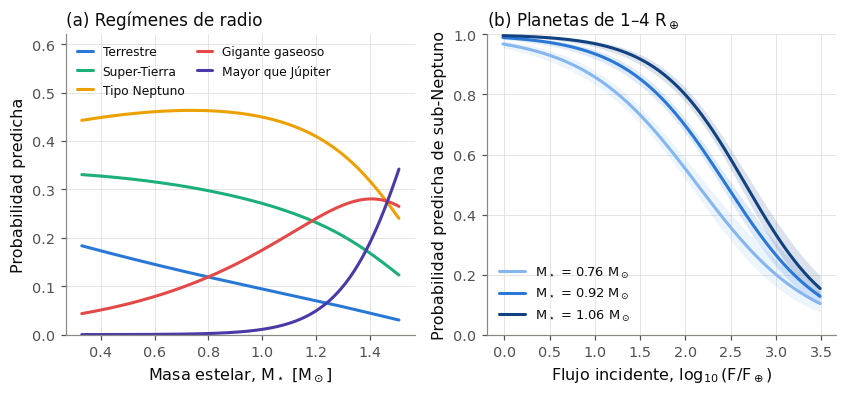

In [6]:
prob_regimen = pd.read_csv(DATOS_PROCESADOS / "A1_probabilidades_predichas_vs_st_mass.csv")
prob_sn = pd.read_csv(DATOS_PROCESADOS / "Z_probabilidad_sub_neptuno_vs_logF.csv")

fig, ejes = plt.subplots(1, 2, figsize=(7.8, 3.7))
ax = ejes[0]
for clase in CLASES_RADIO:
    ax.plot(prob_regimen["st_mass"], prob_regimen[clase], color=COLOR_CLASE[clase], label=ETIQUETA_CLASE[clase])
ax.set_xlabel(EJE["st_mass"])
ax.set_ylabel(EJE["prob"])
ax.set_ylim(0, 0.62)
ax.legend(loc="upper left", fontsize=8, ncol=2, columnspacing=1.0, handlelength=1.3)
etiqueta_panel(ax, "a", "Regímenes de radio")

ax = ejes[1]
for (percentil, d), color in zip(prob_sn.groupby("percentil_st_mass", sort=False), RAMPA_ORDINAL):
    ax.fill_between(d["log_insol_calculada"], d["IC95_inf"], d["IC95_sup"], color=color, alpha=0.15, linewidth=0)
    ax.plot(d["log_insol_calculada"], d["probabilidad"], color=color, label=rf"$M_\star$ = {d['st_mass'].iloc[0]:.2f} $M_\odot$")
ax.set_xlabel(EJE["logF"])
ax.set_ylabel("Probabilidad predicha de sub-Neptuno")
ax.set_ylim(0, 1)
ax.legend(loc="lower left", fontsize=8.5)
etiqueta_panel(ax, "b", "Planetas de 1–4 $R_\\oplus$")
fig.tight_layout()
guardar_figura(fig, "S-F1", "sintesis_analisis_I",
               titulo=("Síntesis del análisis I. (a) Probabilidad predicha de cada régimen de radio en función de la masa estelar "
                       "(modelo multinomial B1; período y metalicidad en su mediana). (b) Probabilidad predicha de sub-Neptuno en "
                       "función del flujo incidente para tres masas estelares (modelo M2; bandas: IC 95 %)."),
               seccion="6.5", nota="Alternativa compacta a las figuras A1-F3 y Z-F3; no usar las tres a la vez.")
plt.show()

## 4. Índice de tablas y figuras

`ORDEN_DE_RESULTADOS.md` (en la carpeta `analisis`) lista las tablas y figuras en el orden de presentación de cada sección.

In [7]:
indice_tablas = pd.read_csv(TABLAS / "INDICE_TABLAS.csv")
indice_figuras = pd.read_csv(FIGURAS / "INDICE_FIGURAS.csv")
print(f"{len(indice_tablas)} tablas ({(indice_tablas['destino'] == 'texto principal').sum()} para el texto principal) y "
      f"{len(indice_figuras)} figuras ({(indice_figuras['destino'] == 'texto principal').sum()} para el texto principal).")
escribir_orden_de_resultados()
indice_tablas[["codigo", "seccion", "destino", "titulo"]]

52 tablas (27 para el texto principal) y 20 figuras (14 para el texto principal).
Escrito: ORDEN_DE_RESULTADOS.md


,codigo,seccion,destino,titulo
0,D-T1,6.1.1,anexo,Depuración del catálogo: número de planetas y ...
1,D-T2,6.1.1,anexo,"Variables seleccionadas del catálogo, unidades..."
2,D-T3,6.1.1,texto principal,Estadística descriptiva de las variables plane...
3,D-T4,6.1.1,anexo,Composición del catálogo limpio por método de ...
4,D-T5,6.1.1,texto principal,Regímenes de radio en el catálogo limpio: crit...
5,D-T6,6.1.1,anexo,Clasificaciones auxiliares por masa y período ...
6,D-T7,6.1.1,anexo,Verificación de los parámetros derivados frent...
7,D-T8,6.1.2,texto principal,Submuestras utilizadas en los tres análisis.
8,A1-T1,6.2.1,texto principal,Análisis I: composición de la muestra de plane...
9,A1-T2,6.2.1,anexo,Análisis I: prueba de Kruskal-Wallis de la mas...


## Lectura de los resultados

- La estrella aporta información en los tres niveles, pero en magnitudes muy distintas: mucha en los regímenes de radio, moderada en el equilibrio entre super-Tierras y sub-Neptunos, y poca en la masa de los planetas pequeños y en la arquitectura.
- La masa estelar es el predictor más consistente: su efecto se distingue de cero en el modelo estelar de los análisis I y III (la única excepción es el contraste entre planetas tipo Neptuno y super-Tierras). En la masa de los planetas pequeños (análisis II) no se distingue de cero.
- La metalicidad importa sobre todo para los gigantes gaseosos y los planetas tipo Neptuno; en el resto, su efecto es pequeño o no se distingue de cero.
- El resultado más débil es el de los sistemas *gapped*: no se mantiene al restringir a sistemas con todos sus planetas en tránsito (tabla A3-T9).